# Word Level OCR for Persian Language
## Based on Recurrent Neural Networks
Amirabbas Asadi, amir137825@gmail.com

In [1]:
import sys
from pathlib import Path

current_path = Path.cwd().resolve()

PROJECT_ROOT = next(
    (path for path in (current_path, *current_path.parents) if (path / "pyproject.toml").is_file()),
    None,
)

if PROJECT_ROOT is None:
    raise FileNotFoundError("Could not find the project root.")

sys.path.insert(0, str(PROJECT_ROOT))

## Requirements
- Pandas, Numpy
- Pytorch
- OpenCV
- imgaug

## Dataset
I created a Synthetic dataset called Shotor containing 120000 images and correspond words.  
[Download The Dataset](https://github.com/amirabbasasadi/Shotor)

## Loading and using images

In [2]:
# from imgaug import augmenters as iaa
import os
import torch
import pandas as pd
from skimage import io, transform
import numpy as np
import seaborn as sns

sns.set()
sns.set_style("dark")
import matplotlib.pyplot as plt
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, utils
import torchvision
from random import randint

### Some configurations

In [3]:
# input images width
img_width = 100
# input images height
img_height = 50
# every image will be splited into <img_splits> parts
img_splits = 20
# maximum length of each word
word_max_len = 15
# device for tensors
# current version is sequential and GPU has not a significant effect
# I didn't test the model on GPU
device = "cpu"

### Set dataset path

In [4]:
dataset_path = "datasets/typed_words_images/images/"
csv_words_path = "datasets/typed_words_images/labels.csv"

### Creating dataset object
It is easier to define a dataset object for using data for Pytorch models

In [5]:
class PersianOCR(Dataset):
    """Persian Hand-Written dataset."""

    def __init__(self, csv_file, root_dir, transform=None):
        """
        Args:
            csv_file (string): Path to the csv file with annotations.
            root_dir (string): Directory with all the images.
            transform (callable, optional): Optional transform to be applied
                on a sample.
        """
        self.root_dir = root_dir
        self.transform = transform
        # read the csv file
        self.csv = pd.read_csv(csv_file)

    def __len__(self):
        return self.csv.shape[0]

    def __getitem__(self, idx):
        if torch.is_tensor(idx):
            idx = idx.tolist()
        img_name = os.path.join(self.root_dir, str(self.csv.iloc[idx, 0]) + ".tif")
        word = self.csv.iloc[idx, 1]
        image = io.imread(img_name)

        item = {"image": image, "word": word}

        if self.transform:
            item = self.transform(item)

        return item


dataset = PersianOCR(csv_words_path, dataset_path)

### Checking the raw dataset
Take a look at some random words from dataset

['بوستانت', 'بدست', 'شنیدنیمان', 'راستین', 'توضیحهایمان', 'وقف', 'گیرهت', 'جهاننش', 'امتحانهایش', 'اکسترودرمان', 'خاطیترینت', 'تامیر', 'مقارن', 'بی', 'نمی زادی', 'قسمتی ها', 'لچک', 'برگزیده ای', 'میدعاگویی', 'کروبمان']


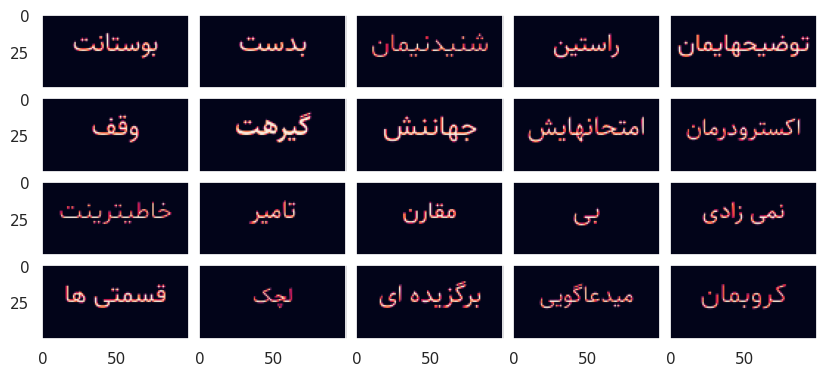

In [6]:
from mpl_toolkits.axes_grid1 import ImageGrid

fig = plt.figure(figsize=(10.0, 12.0))
grid = ImageGrid(fig, 111, nrows_ncols=(4, 5), axes_pad=0.1)

images = []
words = []
for _ in range(20):
    rand = randint(0, len(dataset) - 1)
    images.append(dataset[rand]["image"])
    words.append(dataset[rand]["word"])

for ax, im in zip(grid, images):
    ax.imshow(im)
print(words)
plt.show()

### Converting Words and Images to Pytorch Tensors
We should define all persian alphabets.
Also we define `S` as start token and `E` as end token and `-` as blank character which is used for CTCLoss that we wanna use and is different from space character.

In [7]:
# define all persian alphabets
pchars = "آ ا ب پ ت ث ج چ ح خ د ذ ر ز ژ س ش ص ض ط ظ ع غ ف ق ک گ ل م ن و ه ی ئ"
pchars = ["-", " ", "S", "E"] + pchars.split(" ")
letter_to_index = {}
for i in range(len(pchars)):
    letter_to_index[pchars[i]] = i
enc_dim = len(pchars)

In [8]:
class ToTensor(object):
    """Convert ndarrays in sample to Tensors."""

    def __call__(self, sample):
        image, word = sample["image"], sample["word"]
        image = image.reshape(-1, img_height, img_width)
        if len(word) > word_max_len:
            word = word[:word_max_len]
        word = word + "E"
        original_word = [[letter_to_index[c]] for c in word]
        return {"image": torch.from_numpy(image).double(), "word": torch.LongTensor(original_word)}

In [9]:
import re


def clean_ctc(s):
    # remove repeated
    word = ""
    prev = ""
    for c in s:
        if c != prev:
            word += c
        prev = c
    word = re.sub("[\-SE]", "", word)
    return word

In [10]:
def tensor_to_word(word_tensor):
    word_tensor = word_tensor.max(2)[1].view(-1)
    word = ""
    for i in range(word_tensor.size(0)):
        word += pchars[word_tensor[i]]
    return clean_ctc(word)

In [11]:
def indice_to_word(indices):
    word = ""
    for i in indices:
        word += pchars[i]
    return word

### Augmentation Pipeline
using imgaug we can define an Augmentation pipeline. It helps to train a robust model and useable for more realistic data. It randomly applies some of 5 augmentations.

In [12]:
# class ImageAug(object):
#     """Apply Image Augmentation on style and output"""

#     def __call__(self, sample):
#         image, word = sample['image'], sample['word']
#         aug = iaa.SomeOf((0, 5), [
#             iaa.Affine(scale={"x": (0.80, 1.20), "y": (0.80, 1.20)}),
#             iaa.Affine(translate_percent={"x": (-0.2, 0.2), "y": (-0.2, 0.2)}),
#             iaa.Add((-30, 30)),
#             iaa.Multiply((0.80, 1.20)),
#             iaa.GaussianBlur(sigma=(0, 0.2))
#         ])
#         image = aug(images=image)
#         return {'image': image,
#                 'word': word}


### Create Dataset with Transformations

In [13]:
# transformed_dataset = PersianOCR(csv_words_path, dataset_path,
#                                  transform=transforms.Compose([ImageAug(), ToTensor()]))

transformed_dataset = PersianOCR(csv_words_path, dataset_path, transform=transforms.Compose([ToTensor()]))


dataloader = DataLoader(transformed_dataset, batch_size=1, shuffle=True)

### See some samples from transformed dataset

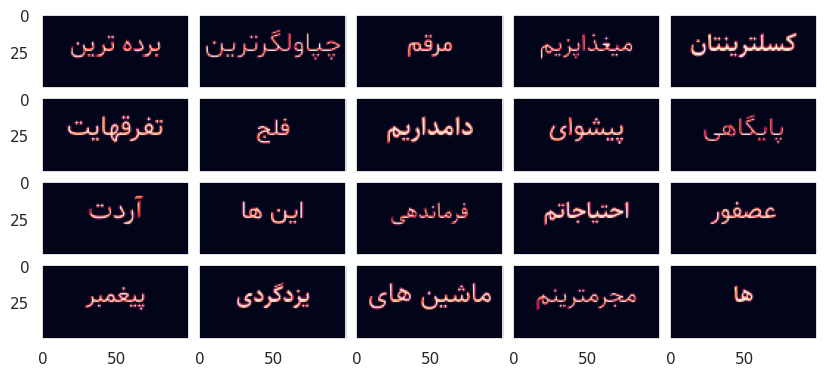

In [14]:
fig = plt.figure(figsize=(10.0, 12.0))
grid = ImageGrid(fig, 111, nrows_ncols=(4, 5), axes_pad=0.1)

images = []
for i, batch in enumerate(dataloader):
    images.append(batch["image"][0][0])
    if i >= 20:
        break

for ax, im in zip(grid, images):
    ax.imshow(im)

plt.show()

## Defining a Recurrent Neural Network in Pytorch

In [15]:
import torch.nn as nn


class OCRNet(nn.Module):
    def __init__(self, img_size, hidden_size):
        super(OCRNet, self).__init__()
        self.hidden_size = hidden_size
        self.img_size = img_size
        self.enc_img_size = 200
        self.fc1 = nn.Linear(self.img_size, 450)
        self.fc2 = nn.Linear(450, self.enc_img_size)
        self.drop = nn.Dropout(p=0.1)
        self.act = nn.CELU()
        self.i2h = nn.Linear(self.enc_img_size + enc_dim + self.hidden_size, 80)
        self.h2h = nn.Linear(80, 60)
        self.h2h2 = nn.Linear(60, self.hidden_size)
        self.i2o = nn.Linear(self.enc_img_size + enc_dim + self.hidden_size, 200)
        self.o2o = nn.Linear(200, enc_dim)
        self.softmax = nn.LogSoftmax(dim=1)

    def forward(self, x, input, hidden):
        x = x.reshape((1, -1))
        x = self.act(self.fc1(x))
        x = self.act(self.fc2(x))
        x = self.drop(x)
        combined = torch.cat((x, input.view((1, -1)), hidden.view((1, -1))), 1)
        hidden = self.act(self.i2h(combined))
        hidden = self.act(self.h2h(hidden))
        hidden = self.h2h2(hidden)
        output = self.act(self.i2o(combined))
        output = self.o2o(output)
        output = self.softmax(output)

        return output, hidden


net = OCRNet(int(img_width / img_splits) * img_height, enc_dim).double()
net = net.to(device)
print(net)
print(f"Number of Parameters: {sum(p.numel() for p in net.parameters() if p.requires_grad):,}")

OCRNet(
  (fc1): Linear(in_features=250, out_features=450, bias=True)
  (fc2): Linear(in_features=450, out_features=200, bias=True)
  (drop): Dropout(p=0.1, inplace=False)
  (act): CELU(alpha=1.0)
  (i2h): Linear(in_features=276, out_features=80, bias=True)
  (h2h): Linear(in_features=80, out_features=60, bias=True)
  (h2h2): Linear(in_features=60, out_features=38, bias=True)
  (i2o): Linear(in_features=276, out_features=200, bias=True)
  (o2o): Linear(in_features=200, out_features=38, bias=True)
  (softmax): LogSoftmax(dim=1)
)
Number of Parameters: 295,526


## Training The Model

### Generating start token

In [16]:
def get_start_token():
    start_token = torch.zeros((1, enc_dim), dtype=torch.double).to(device)
    start_token[0][letter_to_index["S"]] = 1
    return start_token

### Defining Optimizer

In [17]:
import torch.optim as optim

# I suggest to decrease the learning rate after each epoch
# for the first one I used lr = 0.0002 and for the second lr = 0.00005
optim_learning_rate = 0.0002

criterion = nn.CTCLoss()
optimizer = optim.Adam(net.parameters(), lr=optim_learning_rate, betas=(0.5, 0.999))

epochs = 2
mini_batchs = 100
loss_values = []

### Training
After two epochs I saw an acceptable output. on CPU each epoch might take 1-2 hours.

In [18]:
net.train()
step = int(img_width / img_splits)
input_seq_len = torch.tensor([img_splits], dtype=torch.long)
for epoch in range(epochs):
    loss = 0
    mini_batch_loss = 0
    for i, data in enumerate(dataloader, 0):
        # get the input
        image, word = data["image"], data["word"]
        image = image.to(device)
        word = word.to(device)
        # zero the parameter gradients
        optimizer.zero_grad()
        # initialize the RNN hidden state
        hidden = torch.zeros((1, enc_dim)).double().to(device)
        output = get_start_token()
        letters = []
        for j in range(img_splits):
            output, hidden = net(image[:, :, :, step * (img_splits - j - 1) : step * (img_splits - j)], output, hidden)
            letters.append(output)

        # concatinate the outputs
        predicted_word = torch.cat(letters, dim=1).view(img_splits, 1, enc_dim)
        target_seq_len = torch.tensor([word.size(1)], dtype=torch.long)
        
        if i % 1 == 0:
            print(tensor_to_word(predicted_word))
            print(indice_to_word(word.view((1, -1))[0]))
            print(target_seq_len)
            print("=" * 20)
            
        # compairing the output and word based on CTCLoss
        loss = criterion(predicted_word, word.view((1, -1)), input_seq_len, target_seq_len)

        loss.backward()

        optimizer.step()

        mini_batch_loss += loss.item()

        if i % mini_batchs == (mini_batchs - 1):
            print("[%d, %5d] loss: %.5f" % (epoch + 1, i + 1, mini_batch_loss / mini_batchs))

            loss_values.append(mini_batch_loss)

            mini_batch_loss = 0

جلئآحژآمحآضعل
سفالینتE
tensor([8])
کلطعظظعطعل
پنهانE
tensor([6])
ثلطل
مشکلهمE
tensor([7])
ثلعل
لیگE
tensor([4])
ک
تبعتانE
tensor([7])
ک
پرتوافکنتE
tensor([10])
ک
سنتهایE
tensor([7])
ج
غلامبارهE
tensor([9])
ک
اورتگاE
tensor([7])
ک
ثغوریE
tensor([6])
ث
کوهیE
tensor([5])
ک
سرنگونE
tensor([7])
ک
برهیدیE
tensor([7])
ک
می نمودهE
tensor([9])
ک
نیمکتهایتE
tensor([10])
ث
بسردهیE
tensor([7])
ث
نصرE
tensor([4])
ث
فرشتگانE
tensor([8])
ث
فرایندهاییE
tensor([11])
کآن
اسنادیE
tensor([7])
کن
کسیE
tensor([4])
ک
بااینE
tensor([6])
ث
شدندیE
tensor([6])
ک
ریخته اندE
tensor([10])
ث
کیستمE
tensor([6])
ث
متنتانE
tensor([7])
ث
آیدشE
tensor([5])
ک
هورمونیE
tensor([8])
ک
فهمانده امE
tensor([11])
ک
خشکیE
tensor([5])
ک
هم گرE
tensor([6])
ث
داشتهE
tensor([6])
ک
عمرمE
tensor([5])
ث
مراحلE
tensor([6])
ک
تاثربارهاE
tensor([10])
ک
عینکE
tensor([5])
ک
میگذاریE
tensor([8])
ث
نچشمE
tensor([5])
ث
تحاشیE
tensor([6])
ک
وجبهاییE
tensor([8])

موخرهایشانE
tensor([11])
ک
لکلE
tensor([4])
کا
تبلیغاتE
tensor([8])
ک
میE
tensor([3]

KeyboardInterrupt: 

### Checking The Loss values

In [ ]:
sns.set_palette(sns.dark_palette("purple"))
fig, ax = plt.subplots(figsize=(10, 4))
plot = sns.lineplot(ax=ax, y=loss_values, x=range(len(loss_values)))
plot.set_title("Training Loss")
plot.set_xlabel("steps")
plot.set_ylabel("CTC Loss")
plt.show()

## Using The Model for converting a page

### Cleaning The Ouput
Due to the CTCLoss we should clear the ouput from repeated characters then `-` (blank) characters. 

In [ ]:
import re


def clean_ctc(s):
    # remove repeated
    word = ""
    prev = ""
    for c in s:
        if c != prev:
            word += c
        prev = c
    word = re.sub("[\-SE]", "", word)
    return word

### Converting Output Tensor To Word

In [ ]:
def tensor_to_word(word_tensor):
    word_tensor = word_tensor.max(2)[1].view(-1)
    word = ""
    for i in range(word_tensor.size(0)):
        word += pchars[word_tensor[i]]
    return clean_ctc(word)

### Transforming Numpy Images for evaluation

In [ ]:
def transform_numpy_image(img):
    # scale the image
    img = img.reshape(1, 1, 50, 100)
    tensor = torch.from_numpy(img).double().to(device)
    return tensor

### Feeding Image to Model 

In [ ]:
def image_to_word(img):
    tensor = transform_numpy_image(img)
    prediction = None
    net.eval()
    with torch.no_grad():
        hidden = torch.zeros((1, enc_dim)).double().to(device)
        output = get_start_token()
        letters = []
        for j in range(img_splits):
            step = int(img_width / img_splits)
            output, hidden = net(tensor[:, :, :, step * (img_splits - j - 1) : step * (img_splits - j)], output, hidden)
            letters.append(output)
        prediction = torch.cat(letters, dim=0).view(img_splits, 1, enc_dim)
    return tensor_to_word(prediction)

### Reading The Text Image

In [ ]:
import cv2

%matplotlib inline
image_path = "test_page.png"

img = cv2.imread(image_path, cv2.IMREAD_COLOR)
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

fig, ax = plt.subplots(figsize=(14, 5))
ax.imshow(gray, interpolation="nearest")

### Thresholding The Image

In [ ]:
ret, thresh = cv2.threshold(gray, 0, 255, cv2.THRESH_OTSU | cv2.THRESH_BINARY_INV)
fig, ax = plt.subplots(figsize=(14, 5))
ax.imshow(thresh, interpolation="nearest")

### Using dilation to segment the words

In [ ]:
rect_kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (2, 3))
dilation = cv2.dilate(thresh, rect_kernel, iterations=3)
fig, ax = plt.subplots(figsize=(14, 5))
ax.imshow(dilation, interpolation="nearest")

### Finding The Contours

In [ ]:
contours, hierarchy = cv2.findContours(dilation, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
img_contours = img.copy()
for cnt in contours:
    x, y, w, h = cv2.boundingRect(cnt)
    cv2.rectangle(img_contours, (x, y), (x + w, y + h), (0, 255, 0), 1)
fig, ax = plt.subplots(figsize=(14, 5))
ax.imshow(img_contours, interpolation="nearest")

### Sorting The Contours

In [ ]:
from functools import cmp_to_key


def rectCmp(r1, r2):
    if abs(r1[1] - r2[1]) < 20:
        return r2[0] - r1[0]
    return r1[1] - r2[1]


bounding_rects = [cv2.boundingRect(c) for c in contours]
bounding_rects.sort(key=cmp_to_key(rectCmp))

### Extract Images

In [ ]:
def extract_images(rects, image):
    images = []
    for r in rects:
        x, y, w, h = r
        H = 50
        W = 100
        Y = int((H - h) / 2) - 5
        X = int((W - w) / 2) - 5
        c = np.zeros((H, W))
        c[Y : Y + h, X : X + w] = 1 - image[y : y + h, x : x + w]
        c[c < 70] = 0
        c *= 1.8
        c[c > 255] = 255
        c = np.floor(c)
        images.append(c)
    return images


test_images = extract_images(bounding_rects, gray)

## Final Result
After 2 epochs the result should be meangful

In [ ]:
" ".join([image_to_word(image) for image in test_images])

## References
This paper helped me a lot, however my architecture is not same
- https://arxiv.org/abs/1805.09441
- [Pytorch Tutorial on RNNs](https://pytorch.org/tutorials/intermediate/char_rnn_classification_tutorial.html)  
For word segmentation using dilation see this:
- https://stackoverflow.com/a/10970473/4334320

The text of the image which I used to show the final result is a translation of this book:
- The Theory That Would Not Die, Sharon McGrayne